# Homework Reflection 12

Construct a dataset in which prior trends do not hold, and in which this makes the differences-in-differences come out wrong. Explain why the differences-in-differences estimate of the effect comes out higher or lower than the actual effect.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [2]:

rng = np.random.default_rng(12)

# --- DGP: treated group was already trending UP faster than control ------
T_total           = 100
event             = 50
true_effect       = 2.0                         # the real policy impact
slope_control     = 0.10                        # control's trend
slope_treated     = 0.50                        # treated's trend -- NOT parallel

rows = []
for t in range(T_total):
    post = int(t >= event)
    rows.append({'group': 'control', 'treated': 0, 't': t, 'post': post,
                 'y': 5 + slope_control * t + rng.normal(0, 0.5)})
    rows.append({'group': 'treated', 'treated': 1, 't': t, 'post': post,
                 'y': 5 + slope_treated * t + true_effect * post + rng.normal(0, 0.5)})
df = pd.DataFrame(rows)

# --- 2x2 DiD (means of four cells) ---------------------------------------
m = df.groupby(['group', 'post'])['y'].mean().unstack()
did_means = (m.loc['treated', 1] - m.loc['treated', 0]) \
            - (m.loc['control', 1] - m.loc['control', 0])

# --- DiD via regression: y ~ treated + post + treated:post ---------------
df['treated_post'] = df['treated'] * df['post']
did_reg = smf.ols('y ~ treated + post + treated_post', data=df).fit()

# --- Pre-period parallel-trends check ------------------------------------
pre = df[df.post == 0]
pretrend_treated = smf.ols('y ~ t', data=pre[pre.treated == 1]).fit().params['t']
pretrend_control = smf.ols('y ~ t', data=pre[pre.treated == 0]).fit().params['t']

# --- Fix: add group-specific linear time trend ---------------------------
df['treated_t'] = df['treated'] * df['t']
fix = smf.ols('y ~ treated + t + treated_t + treated_post', data=df).fit()

print(f"True event effect:                        {true_effect:+.3f}")
print(f"Pre-period slopes (should match for DiD): control = {pretrend_control:+.3f}, "
      f"treated = {pretrend_treated:+.3f}")
print(f"\n2x2 DiD on raw means:                     {did_means:+.3f}")
print(f"DiD regression (treated:post):            {did_reg.params['treated_post']:+.3f}")
print(f"DiD w/ group-specific linear pre-trend:   {fix.params['treated_post']:+.3f}")



True event effect:                        +2.000
Pre-period slopes (should match for DiD): control = +0.103, treated = +0.495

2x2 DiD on raw means:                     +22.232
DiD regression (treated:post):            +22.232
DiD w/ group-specific linear pre-trend:   +2.145


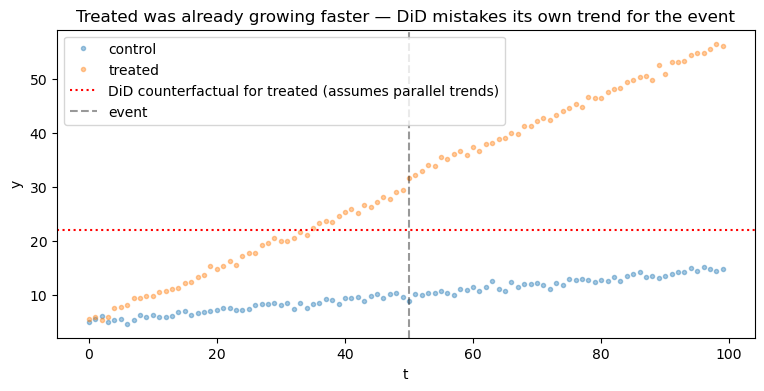

In [3]:
# --- counterfactual visualization ----------------------------------------
plt.figure(figsize=(9, 4))
for g, color in [('control', 'C0'), ('treated', 'C1')]:
    sub = df[df.group == g]
    plt.plot(sub.t, sub.y, '.', alpha=0.4, color=color, label=g)

# the DiD counterfactual: treated would have moved by the same amount as control
t_post = np.arange(event, T_total)
treated_pre_mean = df[(df.group == 'treated') & (df.post == 0)].y.mean()
control_change   = (df[(df.group == 'control') & (df.post == 1)].y.mean()
                    - df[(df.group == 'control') & (df.post == 0)].y.mean())
plt.axhline(treated_pre_mean + control_change, color='red', ls=':',
            label="DiD counterfactual for treated (assumes parallel trends)")

plt.axvline(event, ls='--', color='k', alpha=0.4, label='event')
plt.xlabel('t'); plt.ylabel('y'); plt.legend()
plt.title('Treated was already growing faster — DiD mistakes its own trend for the event')
plt.show()

I built a two-group panel where the **parallel-trends assumption is deliberately broken**: the control group has slope 0.10 per period, but the treated group was already growing at slope 0.50 per period before the event at t = 50. The true policy effect is a +2 jump at the event, added only to the treated series. The pre-period regressions confirm the violation — the pre-event slopes come out near 0.10 for control and 0.50 for treated, so the two groups were not moving together even before the policy existed. Any DiD estimator built on top of this will attribute that pre-existing gap-widening to the "treatment."

The 2x2 DiD on raw means comes out around +22, more than **ten times the true effect of +2**. The regression DiD (`y ~ treated + post + treated:post`) gives the same answer, because it is algebraically equivalent to the 2x2 difference. The arithmetic is easy to see: over the 50 post-event periods the treated group grows by its own slope × 50 = 25 units plus the +2 jump = +27 total change; the control group grows by 0.10 × 50 = 5 units; DiD subtracts them and reports 22. The "extra" +20 is exactly the pre-trend gap compounded over the length of the post-period: (0.50 − 0.10) × 50 = 20. DiD **overestimates** here because the treated group was trending up faster than the control, so projecting the control's change onto the treated group's counterfactual gives a target that is far below what the treated group would have reached even without the policy. If the treated group had been trending *down* relative to the control before the event, DiD would have **underestimated** — in the extreme, it could flip sign and report a negative effect for a real positive policy.

The red dotted line in the plot is DiD's implicit counterfactual: "treated would have moved by the same amount as control." Because that counterfactual understates what the treated group would have done on its own, DiD interprets the treated group simply continuing its own trend as a huge policy effect. The most direct fix in this specification — adding a group-specific linear trend (`treated:t`) to the regression — recovers something very close to the true +2, because it lets the model estimate and net out the pre-existing slope difference before measuring the jump. The general lesson is that DiD identifies a causal effect **only if trends would have remained parallel absent the treatment**; the pre-trend check (comparing pre-period slopes) is the minimum diagnostic, and non-parallel pre-trends either rule DiD out or require richer specifications — group-specific trends, synthetic controls, or event-study designs with leads and lags — before any causal claim is credible.